<a href="https://colab.research.google.com/github/kouheisia/PC1/blob/main/ANN_BreastCancer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from google.colab import drive
drive.mount('/content/drive')
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
   confusion_matrix,
   ConfusionMatrixDisplay,
   classification_report,
   accuracy_score
)

In [60]:
df = pd.read_csv("/content/drive/MyDrive/PC1/breast-cancer.csv")
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [61]:
class_names = ["Benign", "Malignant"]
y = (df["diagnosis"] == "M").astype(int).values
X = df.drop(columns=["diagnosis"])

print("Shape:", X.shape)
print("Class counts:", {str(k): int(v) for k, v in zip(class_names, np.bincount(y))})

Shape: (569, 31)
Class counts: {'Benign': 357, 'Malignant': 212}


In [62]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [63]:
def build_baseline():
    model = Sequential([
        Input(shape=(X_train.shape[1],)),
        Dense(16, activation="relu"),
        Dense(8, activation="relu"),
        Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=Adam(0.001),
                  loss="binary_crossentropy",
                  metrics=["accuracy"])
    return model

baseline = build_baseline()
baseline.summary()
hist_base = baseline.fit(X_train, y_train, validation_split=0.2,
                         epochs=50, batch_size=32, verbose=0)

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_30 (Dense)                │ (None, 16)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 657 (2.57 KB)

 Trainable params: 657 (2.57 KB)

 Non-trainable params: 0 (0.00 B)

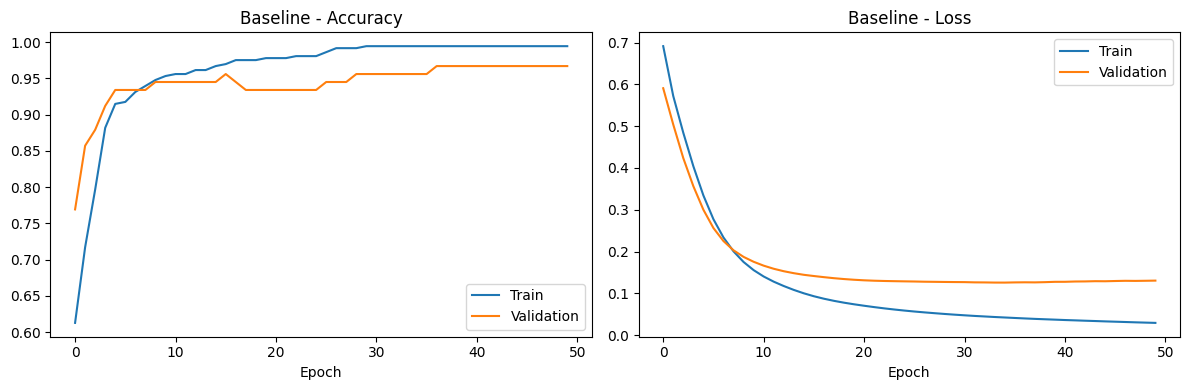

In [64]:
def plot_history(history, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(history.history["accuracy"], label="Train")
    ax[0].plot(history.history["val_accuracy"], label="Validation")
    ax[0].set_title(f"{title} - Accuracy")
    ax[0].set_xlabel("Epoch"); ax[0].legend()
    ax[1].plot(history.history["loss"], label="Train")
    ax[1].plot(history.history["val_loss"], label="Validation")
    ax[1].set_title(f"{title} - Loss")
    ax[1].set_xlabel("Epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()

plot_history(hist_base, "Baseline")

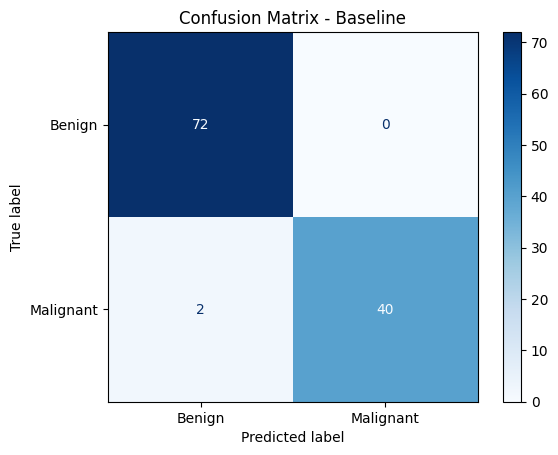


=== Classification Report: Baseline ===
              precision    recall  f1-score   support

      Benign       0.97      1.00      0.99        72
   Malignant       1.00      0.95      0.98        42

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

Accuracy: 0.9825


In [65]:
def evaluate(model, name):
    y_pred = (model.predict(X_test, verbose=0) > 0.5).astype(int).ravel()
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues")
    plt.title(f"Confusion Matrix - {name}")
    plt.show()

    print(f"\n=== Classification Report: {name} ===")
    print(classification_report(y_test, y_pred, target_names=class_names))
    acc = accuracy_score(y_test, y_pred)
    print(f"Accuracy: {acc:.4f}")
    return acc

acc_base = evaluate(baseline, "Baseline")

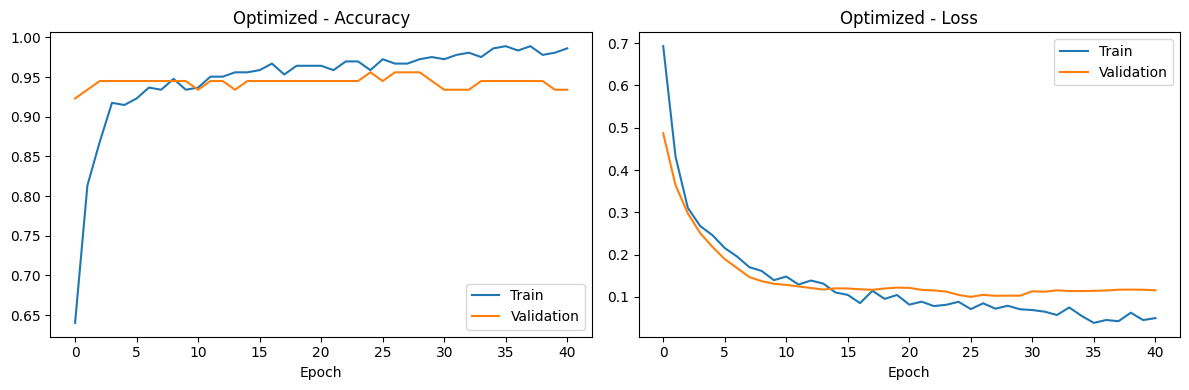

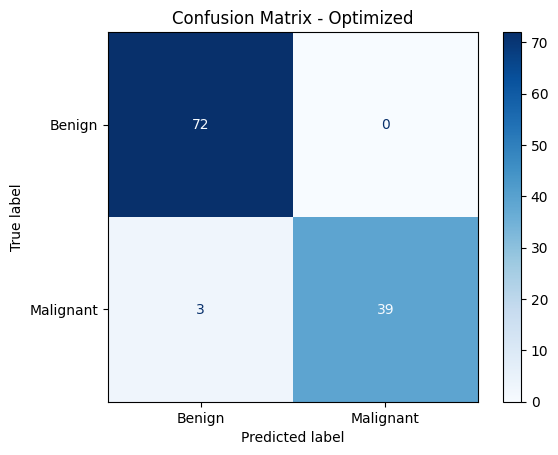


=== Classification Report: Optimized ===
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114

Accuracy: 0.9737

Baseline accuracy : 0.9825
Optimized accuracy: 0.9737


In [58]:
def build_optimized():
    model = Sequential([
        Input(shape=(X_train.shape[1],)),
        Dense(64, activation="relu"),
        BatchNormalization(),
        Dropout(0.3),
        Dense(32, activation="relu"),
        BatchNormalization(),
        Dropout(0.3),
        Dense(16, activation="relu"),
        Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=Adam(0.001),
                  loss="binary_crossentropy",
                  metrics=["accuracy"])
    return model

callbacks = [
    EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5),
]

optimized = build_optimized()
hist_opt = optimized.fit(X_train, y_train, validation_split=0.2,
                         epochs=200, batch_size=16,
                         callbacks=callbacks, verbose=0)

plot_history(hist_opt, "Optimized")
acc_opt = evaluate(optimized, "Optimized")

print(f"\nBaseline accuracy : {acc_base:.4f}")
print(f"Optimized accuracy: {acc_opt:.4f}")

In [59]:
best = optimized if acc_opt >= acc_base else baseline

samples = X_test[:5]
probs = best.predict(samples, verbose=0).ravel()
for i, p in enumerate(probs):
    label = class_names[int(p > 0.5)]
    actual = class_names[y_test[i]]
    print(f"Sample {i+1}: predicted = {label} (prob malignant = {p:.3f}) | actual = {actual}")

Sample 1: predicted = Benign (prob malignant = 0.000) | actual = Benign
Sample 2: predicted = Malignant (prob malignant = 1.000) | actual = Malignant
Sample 3: predicted = Benign (prob malignant = 0.022) | actual = Benign
Sample 4: predicted = Malignant (prob malignant = 0.946) | actual = Malignant
Sample 5: predicted = Benign (prob malignant = 0.264) | actual = Benign
